# Legacy Magi-only extraction — historical outputs
These outputs predate the Magi + Paddle correction. They do not validate the current pipeline. Run NarrationModelwBubbles_Test.ipynb for the current complete one-page pipeline.


In [1]:
import os
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
from pathlib import Path
import sys, json
ROOT = Path(r'C:/Users/ESHAAN/BYTE/Applied-Task/Magi/FINETUNING-EXPERMENTS/NarrationModelwBubbles')
sys.path.insert(0, str(ROOT))
for name in ['config', 'model', 'bubble_features', 'one_page_inputs']:
    sys.modules.pop(name, None)
import torch
from config import CONFIG, BUBBLE_SETTINGS
from bubble_features import sha256, save_json
from one_page_inputs import prepare_page, classify_page
from IPython.display import display
from PIL import Image
import pandas as pd
print('Interpreter:', sys.executable)
print('CUDA:', torch.cuda.is_available())


Interpreter: c:\Users\ESHAAN\BYTE\godfather.venv\Scripts\python.exe
CUDA: True


## Settings
Change PAGE_PATH to reuse on another page. RAW_MAGI_CACHE=None runs and caches original Magi OCR locally. An existing raw cache is accepted only with a matching page hash.


In [2]:
PAGE_PATH = ROOT.parent.parent / 'TaskData/test/images/seq_14469aeb38963085/02.png'
RAW_MAGI_CACHE = ROOT.parent.parent / 'paddleOCR-Magi/cache_inference/test/seq_14469aeb38963085/magi_raw.json'
# Set None until training has produced a checkpoint, then point to runs/best.pt.
CHECKPOINT_PATH = None
# CHECKPOINT_PATH = ROOT / 'runs/best.pt'
NARRATION_THRESHOLD = 0.5
assert PAGE_PATH.is_file(), PAGE_PATH


## Prepare/reuse crops and inputs
Nonempty Magi text boxes must have at least 80% of their area inside a bubble. One best bubble per text; unused/empty candidates are rejected and audited. Each retained crop supplies a frozen, spatially averaged DETR encoder embedding. Original text-query features remain for uncovered text.


In [3]:
inputs, OUTPUT_DIR = prepare_page(PAGE_PATH, RAW_MAGI_CACHE)
print('Cached tensors:', {k: tuple(v.shape) for k,v in inputs['batch'].items()})
print('Original text boxes:', len(inputs['sequence']['boxes']))
display(pd.DataFrame(inputs['summary']))


CACHE one-page inputs: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationModelwBubbles\cache\one_page\seq_14469aeb38963085_02_03ef9953d27e\inputs_95f38eb79b488350.pt
Cached tensors: {'text': (1, 14, 768), 'visual': (1, 14, 256), 'tail': (1, 14, 2), 'geometry': (1, 14, 4), 'page': (1, 14), 'attention_mask': (1, 14)}
Original text boxes: 14


,sequence_id,page_index,page_file,candidates,kept,rejected,covered_texts,fallback_texts,cache,preview,signature
0,seq_14469aeb38963085_02_03ef9953d27e,0,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskDat...,16,12,4,12,2,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUN...,C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUN...,1dfe29dab446059cf3934248bc8e384e3b58edea9194c9...


## Inspect retained and rejected bubbles
Green = retained; red = rejected. Crops contain original RGB pixels; DETR receives grayscale-to-RGB crops, matching Magi preprocessing.


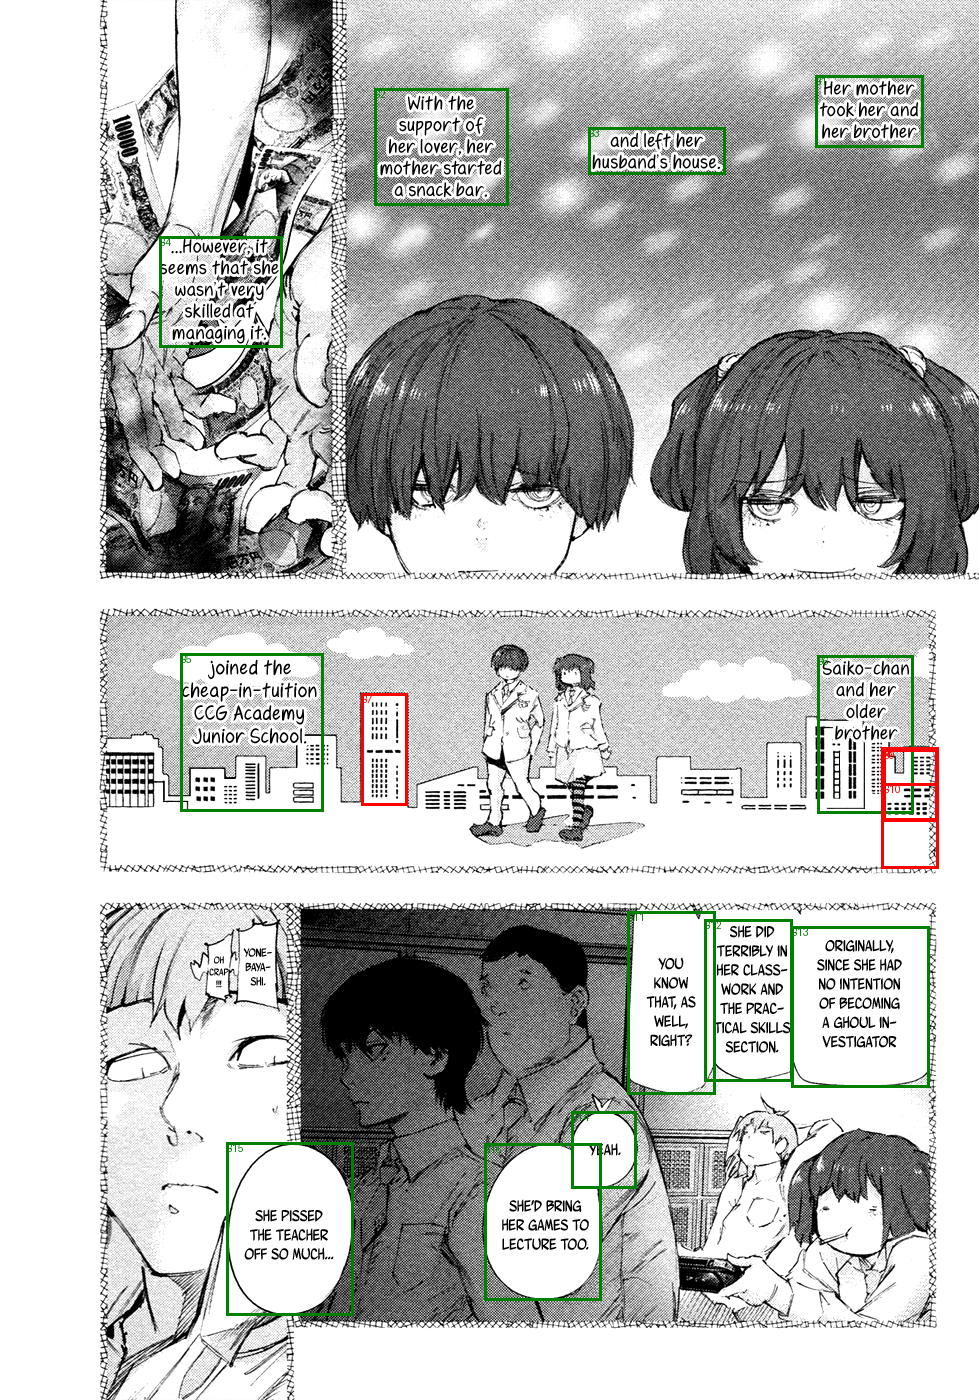

,box,confidence,bubble_id,text_ids,kept,reason,crop
0,"[815, 75, 923, 147]",0.904156,B1,[PG1:T1],True,nonempty_magi_text,crops/B1.png
1,"[374, 88, 508, 205]",0.888981,B2,[PG1:T3],True,nonempty_magi_text,crops/B2.png
2,"[588, 127, 725, 174]",0.809839,B3,[PG1:T2],True,nonempty_magi_text,crops/B3.png
3,"[159, 236, 282, 347]",0.890074,B4,[PG1:T4],True,nonempty_magi_text,crops/B4.png
4,"[180, 653, 323, 811]",0.660857,B5,[PG1:T6],True,nonempty_magi_text,crops/B5.png
5,"[817, 655, 913, 813]",0.700612,B6,[PG1:T5],True,nonempty_magi_text,crops/B6.png
6,"[361, 693, 407, 805]",0.737053,B7,[],False,no_assigned_nonempty_magi_text,NaN
7,"[881, 747, 938, 868]",0.366183,B8,[],False,no_assigned_nonempty_magi_text,NaN
8,"[883, 749, 937, 821]",0.445805,B9,[],False,no_assigned_nonempty_magi_text,NaN
9,"[883, 783, 937, 820]",0.325667,B10,[],False,no_assigned_nonempty_magi_text,NaN


B1 Magi text IDs: ['PG1:T1']


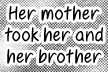

B2 Magi text IDs: ['PG1:T3']


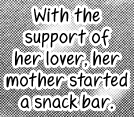

B3 Magi text IDs: ['PG1:T2']


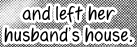

B4 Magi text IDs: ['PG1:T4']


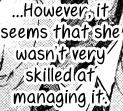

B5 Magi text IDs: ['PG1:T6']


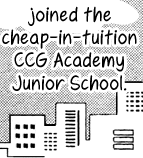

B6 Magi text IDs: ['PG1:T5']


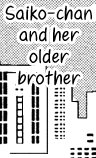

B11 Magi text IDs: ['PG1:T9']


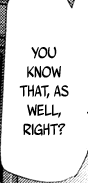

B12 Magi text IDs: ['PG1:T8']


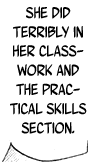

B13 Magi text IDs: ['PG1:T7']


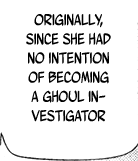

B14 Magi text IDs: ['PG1:T10']


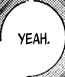

B15 Magi text IDs: ['PG1:T13']


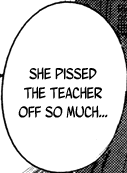

B16 Magi text IDs: ['PG1:T11']


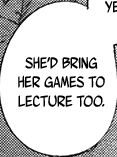

In [4]:
for page in inputs['summary']:
    display(Image.open(page['preview']))
    payload = torch.load(page['cache'], map_location='cpu', weights_only=True)
    display(pd.DataFrame([{k:v for k,v in b.items() if k not in ['crop_sha256']} for b in payload['bubbles']]))
    crop_dir = Path(page['cache']).parent
    for bubble in payload['bubbles']:
        if bubble['kept']:
            print(bubble['bubble_id'], 'Magi text IDs:', bubble['text_ids'])
            display(Image.open(crop_dir / bubble['crop']))


## Optional inference with the trained bubble classifier
Original and DINO checkpoints are incompatible with this representation. The new checkpoint must match the saved feature contract. Prediction caches depend on input tensors, checkpoint SHA256, threshold, and inference code.


In [5]:
from config import fingerprint
if CHECKPOINT_PATH is None:
    print('Crops and embeddings ready. Set CHECKPOINT_PATH after training to classify narration.')
else:
    CHECKPOINT_PATH = Path(CHECKPOINT_PATH)
    prediction_key = fingerprint(dict(inputs=inputs['signature'],
        checkpoint_sha256=sha256(CHECKPOINT_PATH), threshold=NARRATION_THRESHOLD,
        inference_code_sha256=sha256(ROOT / 'one_page_inputs.py'), model_code_sha256=sha256(ROOT / 'model.py')))
    prediction_file = OUTPUT_DIR / f'predictions_{prediction_key[:16]}.json'
    if prediction_file.exists():
        predictions = json.loads(prediction_file.read_text(encoding='utf-8'))
        print('CACHE predictions:', prediction_file)
    else:
        predictions = classify_page(inputs, CHECKPOINT_PATH, NARRATION_THRESHOLD)
        save_json(prediction_file, predictions)
    display(pd.DataFrame(predictions))
    print('Saved:', prediction_file)


Crops and embeddings ready. Set CHECKPOINT_PATH after training to classify narration.
